# Test des modules serial et pyserial

Elaboration d'un algorythme de lecture série des données de la carte

In [31]:
import serial
import serial.tools.list_ports
import matplotlib.pyplot as plt
import numpy

In [32]:
#Global variables

measured_tests = []

In [136]:
#Lists all ports
ports = serial.tools.list_ports.comports()

open_ports = ""
descr = ""

for port, desc, hwid in sorted(ports):
        ##print("{}: {} [{}]".format(port, desc, hwid))
        ##print("{}".format(port))
        descr = "{}".format(desc)
        if (descr == "STM32 STLink - ST-Link VCP Ctrl"):
            open_ports = "{}".format(port)

print("Open ports : ", open_ports)

data_serial = serial.Serial(
    port=open_ports,
    baudrate=921600,#576000,#115200,
    parity=serial.PARITY_NONE,
    stopbits=serial.STOPBITS_ONE,
    bytesize=serial.EIGHTBITS

)
data_serial.writeTimeout = 0 
data_serial.isOpen()
print(data_serial)

Open ports :  /dev/ttyACM0
Serial<id=0x7f0a435de260, open=True>(port='/dev/ttyACM0', baudrate=921600, bytesize=8, parity='N', stopbits=1, timeout=None, xonxoff=False, rtscts=False, dsrdtr=False)


In [135]:
data_serial.close()
data_serial.isOpen()

False

In [134]:
data_serial.isOpen()

True

### RX

In [57]:
# =================================
# IDs TX/RX
# =================================

ID_RX_START = b'0x01'
ID_RX_STOP = b'0x02'
ID_RX_PWM_START = b'0x03'
ID_RX_PWM_STOP = b'0x04'
ID_RX_DUTY_SET = b'0x05'
ID_RX_DIR = b'0x06'
ID_RX_VOLTAGE_SET = b'0x07'
ID_RX_SET_MAG = b'0x08'

ID_RX_ACK = b'0xFF'
ID_RX_CALIBRATE = b'0xFE'
ID_RX_CALIB_ZEROG = b'0xFA'
ID_RX_CALIB_MINUSG = b'0xFB'
ID_RX_CALIB_PLUSG = b'0xFC'

ID_RX_SEND_KP = b'0x0A'
ID_RX_SET_KP = b'0x0B'
ID_RX_SEND_KI = b'0x0C'
ID_RX_SET_KI = b'0x0D'
ID_RX_SEND_KD = b'0x0E'
ID_RX_SET_KD = b'0x0F'

# =================================
# trames
# =================================

def define_trame(msg_id, value, max_size):
    #init
    trame = b''
    byte_length = b''
    
    byte_length = bytes(str(value),'utf-8')
    float_byte_size = len(byte_length)
    index_max_byte = max_size-len(msg_id)-2
    print("index_max_byte :",index_max_byte, " max_size :", max_size)
    trame = msg_id+byte_length[0:index_max_byte]+b';'
    
    #zero filler
    zero_filler = b'0'*(max_size - len(trame)-1)
    trame+= zero_filler
    #EOF Character to end the line, counts as 1 bytes
    trame += bytes('\n', 'utf-8')
    return trame

# =================================
# fonctions d'envoi
# =================================

MSG_MAX_SIZE = 16

def uart_send_start():
    data_serial.write(define_trame(ID_RX_START, 1, MSG_MAX_SIZE))
    
def uart_send_stop():
    data_serial.write(define_trame(ID_RX_STOP, 1, MSG_MAX_SIZE))
    
def uart_send_pwmStart():
    data_serial.write(define_trame(ID_RX_PWM_START, 1, MSG_MAX_SIZE))
    
def uart_send_pwmStop():
    data_serial.write(define_trame(ID_RX_PWM_STOP, 1, MSG_MAX_SIZE))
    
def uart_send_dutyValue(duty_value):
    data_serial.write(define_trame(ID_RX_DUTY_SET, duty_value, MSG_MAX_SIZE))
    
def uart_send_direction(dir_value):
    data_serial.write(define_trame(ID_RX_DIR, dir_value, MSG_MAX_SIZE))
    
def uart_send_voltageValue(voltage_value):
    print("b'' sent : ",data_serial.write(define_trame(ID_RX_VOLTAGE_SET, voltage_value, MSG_MAX_SIZE)))
    
def uart_send_kpAsk(kp_value):
    data_serial.write(define_trame(ID_RX_SET_KP, kp_value, MSG_MAX_SIZE))
    
def uart_send_kpValue():
    data_serial.write(define_trame(ID_RX_SEND_KP, 1, MSG_MAX_SIZE))
    
def uart_send_kiAsk(ki_value):
    data_serial.write(define_trame(ID_RX_SET_KI, ki_value, MSG_MAX_SIZE))
    
def uart_send_kiValue():
    data_serial.write(define_trame(ID_RX_SEND_KI, 1, MSG_MAX_SIZE))
    
def uart_send_kdAsk(kd_value):
    data_serial.write(define_trame(ID_RX_SET_KD, kd_value, MSG_MAX_SIZE))
    
def uart_send_kdValue():
    data_serial.write(define_trame(ID_RX_SEND_KD, 1, MSG_MAX_SIZE))
    
def uart_send_acknowledge():
    data_serial.write(define_trame(ID_RX_ACK, 1, MSG_MAX_SIZE))
    
def uart_send_calibrate():
    data_serial.write(define_trame(ID_RX_CALIBRATE, 1, MSG_MAX_SIZE))
    
def uart_send_calibzeroG():
    data_serial.write(define_trame(ID_RX_CALIB_ZEROG, 1, MSG_MAX_SIZE))
    
def uart_send_calibminusG():
    data_serial.write(define_trame(ID_RX_CALIB_MINUSG, 1, MSG_MAX_SIZE))
    
def uart_send_calibplusG():
    data_serial.write(define_trame(ID_RX_CALIB_PLUSG, 1, MSG_MAX_SIZE))
    
def uart_send_mag(state_int):
    data_serial.write(define_trame(ID_RX_SET_MAG, state_int, MSG_MAX_SIZE))

In [68]:
uart_send_mag(1)

index_max_byte : 10  max_size : 16


In [52]:
uart_send_mag(0)

index_max_byte : 10  max_size : 16


In [9]:
uart_send_start()

index_max_byte : 10  max_size : 16


In [10]:
uart_send_stop()

index_max_byte : 10  max_size : 16


In [61]:
uart_send_dutyValue(100.0)

index_max_byte : 10  max_size : 16


In [62]:
uart_send_dutyValue(0.0)

index_max_byte : 10  max_size : 16


## Calibration accelero

In [219]:
uart_send_calibzeroG()

index_max_byte : 10  max_size : 16


In [220]:
uart_send_calibminusG()

index_max_byte : 10  max_size : 16


In [221]:
uart_send_calibplusG()

index_max_byte : 10  max_size : 16


In [222]:
uart_send_calibrate()

index_max_byte : 10  max_size : 16


## Lecture & Traitement des données

In [193]:
# =================================
# Read
# =================================
def read_data(nline):
    data_serial.reset_input_buffer()
    data_serial.reset_output_buffer()
    
    ##error while reading previous values
    ##kinda flush
    for i in range(0,25):
        data_serial.readline()
    
    it = 0
    print("start reading")
    data_table = []
    while (it != nline):
        # Read data out of the buffer until a carraige return / new line is found
        data = (data_serial.readline()).decode()
        data = data.split(";")
        #print(data)
        
        data_table.append(data)
        it += 1;
        #print(it)
    print("out")
    return data_table

# =================================
# Processing
# =================================
def compute_data_table(dt):
    ndt = []
    tables = []
    
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            data_line[0] = data_line[0].lstrip('\r') #supprime le \r caractere
            
            for i in range(0, len(data_line)):
                if ((i%2) == 1):
                    data_line[i] = float(data_line[i])
        ndt.append(data_line)
    return ndt

# =================================
# Slicing
# =================================
def time_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")): # "0x01" in data_line[k] only for string
                    if ("0x01" in data_line[k]):
                        ndt.append((data_line[k+1])/1000)
                        print("GTEST TIME",(data_line[k+1])/1000)
    
    init_time = ndt[0]
    for j in range(len(ndt)):
        ndt[j] = round(ndt[j] - init_time, 3) #3 digit after . as it is divised by 10e3
    
    return ndt

def pwm_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            ##print(data_line)
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x11" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def adc_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x09" in data_line[k]):
                        ndt.append(data_line[k+1])
                        print(data_line[k+1])
                    
    return ndt

def accel_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x10" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def speed_getTable(dt):
    ndt = []
    for data_line in dt:
        #print("DATA LINE :", data_line, len(data_line))
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x12" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

### Tests

In [198]:
import time
t0 = time.time()
#data_serial.reset_input_buffer()

data_test = read_data(1000)
t1 = time.time()
print(t1-t0)

start reading
out
1.0022172927856445


In [199]:
print(data_test)

[['\r\x000x01', '515574', '0x09', '1.038999', '0x10', '-inf', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '515575', '0x09', '1.039045', '0x10', '-inf', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '515576', '0x09', '1.022240', '0x10', '-inf', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '515577', '0x09', '1.050269', '0x10', '-inf', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '515578', '0x09', '1.044807', '0x10', '-inf', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '515579', '0x09', '1.044792', '0x10', '-inf', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '515580', '0x09', '1.028987', '0x10', '-inf', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '515581', '0x09', '1.048240', '0x10', '-inf', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '515582', '0x09', '1.027471', '0x10', '-inf', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '515583', '0x09', '1.033187', '0x10', '-inf', '0x11', '0', '0x12', '0.00000

In [200]:
computed_data = (compute_data_table(data_test))
print(computed_data)

[['\x000x01', 515574.0, '0x09', 1.038999, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515575.0, '0x09', 1.039045, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515576.0, '0x09', 1.02224, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515577.0, '0x09', 1.050269, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515578.0, '0x09', 1.044807, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515579.0, '0x09', 1.044792, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515580.0, '0x09', 1.028987, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515581.0, '0x09', 1.04824, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515582.0, '0x09', 1.027471, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515583.0, '0x09', 1.033187, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515584.0, '0x09', 1.035617, '0x10', -inf, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 515585.0, '0x09', 1.

In [201]:
time_table = time_getTable(computed_data)
print(len(time_table))
speed_table = speed_getTable(computed_data)
adc_table = adc_getTable(computed_data)
accel_table = accel_getTable(computed_data)
pwm_table = pwm_getTable(computed_data)

GTEST TIME 515.574
GTEST TIME 515.575
GTEST TIME 515.576
GTEST TIME 515.577
GTEST TIME 515.578
GTEST TIME 515.579
GTEST TIME 515.58
GTEST TIME 515.581
GTEST TIME 515.582
GTEST TIME 515.583
GTEST TIME 515.584
GTEST TIME 515.585
GTEST TIME 515.586
GTEST TIME 515.587
GTEST TIME 515.588
GTEST TIME 515.589
GTEST TIME 515.59
GTEST TIME 515.591
GTEST TIME 515.592
GTEST TIME 515.593
GTEST TIME 515.594
GTEST TIME 515.595
GTEST TIME 515.596
GTEST TIME 515.597
GTEST TIME 515.598
GTEST TIME 515.599
GTEST TIME 515.6
GTEST TIME 515.601
GTEST TIME 515.602
GTEST TIME 515.603
GTEST TIME 515.604
GTEST TIME 515.605
GTEST TIME 515.606
GTEST TIME 515.607
GTEST TIME 515.608
GTEST TIME 515.609
GTEST TIME 515.61
GTEST TIME 515.611
GTEST TIME 515.612
GTEST TIME 515.613
GTEST TIME 515.614
GTEST TIME 515.615
GTEST TIME 515.616
GTEST TIME 515.617
GTEST TIME 515.618
GTEST TIME 515.619
GTEST TIME 515.62
GTEST TIME 515.621
GTEST TIME 515.622
GTEST TIME 515.623
GTEST TIME 515.624
GTEST TIME 515.625
GTEST TIME 515.626

In [49]:
import time
import threading

# =================================
# Mix & Mash des fonctions
# =================================

time_table = []
speed_table = []
adc_table = []
accel_table = []
pwm_table = []

def release_accel(te_ms, period_ms):
    print("Thread %s: starting")
    uart_send_start()
    time.sleep((te_ms/period_ms)*0.1)
    print("Thread %s: finishing")
    #uart_send_magnet()
    uart_send_voltageValue(voltage_value=0)

def measure_all(te_ms, period_ms):
    #reboot input buffer
    global time_table, speed_table, adc_table, accel_table, pwm_table
    initial_measure = []
    core_measure = []
    thread_release = threading.Thread(target=release_accel, args=(te_ms,period_ms), daemon = True)
    # =================================
    # Mesures
    # =================================
    print("=== Lancement des mesures ===")
    print("Temps : "+str(te_ms)+"ms")
    print("--> Relaĉhe de l'aimant")
    thread_release.start()
    core_measure = read_data(int((te_ms/period_ms)))
    
    uart_send_stop()
    print("--> Fin de la mesure")
    thread_release.stop()
    # =================================
    # Traitements
    # =================================
    print("=== Traitement des mesures ===")
    print("--> Traitement principal")
    computed_data = (compute_data_table(core_measure))
    print("--> Découpage des tables")
    time_table = time_getTable(computed_data)
    speed_table = speed_getTable(computed_data)
    adc_table = adc_getTable(computed_data)
    accel_table = accel_getTable(computed_data)
    pwm_table = pwm_getTable(computed_data)
    print("--> Retour")

In [62]:
measured_tests.append(measure_all(15000, 10))

=== Lancement des mesures ===
Temps : 10000ms
--> Relaĉhe de l'aimant
Thread %s: starting
index_max_byte : 10  max_size : 16
start reading
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
Thread %s: finishing
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237


AttributeError: 'Thread' object has no attribute 'stop'

In [ ]:
import time
import threading

# =================================
# Mix & Mash des fonctions
# =================================

time_table = []
speed_table = []
adc_table = []
accel_table = []
pwm_table = []

def release_accel(te_ms, period_ms):
    print("Thread %s: starting")
    uart_send_start()
    time.sleep((te_ms/period_ms)*0.1)
    print("Thread %s: finishing")
    #uart_send_magnet()
    uart_send_Duty

def measure_all(te_ms, period_ms):
    #reboot input buffer
    global time_table, speed_table, adc_table, accel_table, pwm_table
    initial_measure = []
    core_measure = []
    thread_release = threading.Thread(target=release_accel, args=(te_ms,period_ms), daemon = True)
    # =================================
    # Mesures
    # =================================
    print("=== Lancement des mesures ===")
    print("Temps : "+str(te_ms)+"ms")
    print("--> Relaĉhe de l'aimant")
    thread_release.start()
    core_measure = read_data(int((te_ms/period_ms)))
    
    uart_send_stop()
    print("--> Fin de la mesure")
    thread_release.stop()
    # =================================
    # Traitements
    # =================================
    print("=== Traitement des mesures ===")
    print("--> Traitement principal")
    computed_data = (compute_data_table(core_measure))
    print("--> Découpage des tables")
    time_table = time_getTable(computed_data)
    speed_table = speed_getTable(computed_data)
    adc_table = adc_getTable(computed_data)
    accel_table = accel_getTable(computed_data)
    pwm_table = pwm_getTable(computed_data)
    print("--> Retour")

In [158]:
print(time_table)
#print(adc_table)

[0.0, 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01, 0.011, 0.012, 0.013, 0.014, 0.015, 0.016, 0.017, 0.018, 0.019, 0.02, 0.021, 0.022, 236.505, 236.506, 236.507, 236.508, 236.509, 236.51, 236.511, 236.512, 236.513, 236.514, 236.515, 236.516, 236.517, 236.518, 236.519, 236.52, 236.521, 236.522, 236.523, 236.524, 236.525, 236.526, 236.527, 236.528, 236.529, 236.53, 236.531, 236.532, 236.533, 236.534, 236.535, 236.536, 236.537, 236.538, 236.539, 236.54, 236.541, 236.542, 236.543, 236.544, 236.545, 236.546, 236.547, 236.548, 236.549, 236.55, 236.551, 236.552, 236.553, 236.554, 236.555, 236.556, 236.557, 236.558, 236.559, 236.56, 236.561, 236.562, 236.563, 236.564, 236.565, 236.566, 236.567, 236.568, 236.569, 236.57, 236.571, 236.572, 236.573, 236.574, 236.575, 236.576, 236.577, 236.578, 236.579]


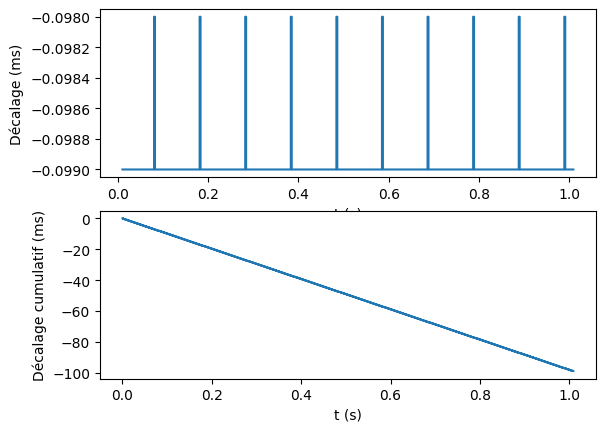

In [202]:
def compute_error_time(time_table, period):
    time_error_table =[0]*len(time_table)
    cumulative_error =[0]*len(time_table)
    for i in range(1, len(time_table)):
        if (i == 1):
            time_error_table[i] = round(time_table[i] - period, 3)
            cumulative_error[i] = round(time_table[i] - period, 3)
        elif (i != 1):
            time_error_table[i] = round(time_table[i] - time_table[i-1] - period, 3)
            if (round(time_table[i] - time_table[i-1] - period, 3) < period):
                cumulative_error[i] = cumulative_error[i-1] + round(time_table[i] - time_table[i-1] - period, 3)
            else:
                cumulative_error[i] = cumulative_error[i-1]
            
            
    plt.subplot(2,1,1)
    plt.step(time_table[10:len(time_table)],time_error_table[10:len(time_table)])
    plt.xlabel("t (s)")
    plt.ylabel("Décalage (ms)")
    
    plt.subplot(2,1,2)
    plt.step(time_table,cumulative_error)
    plt.xlabel("t (s)")
    plt.ylabel("Décalage cumulatif (ms)")

compute_error_time(time_table, 0.1)

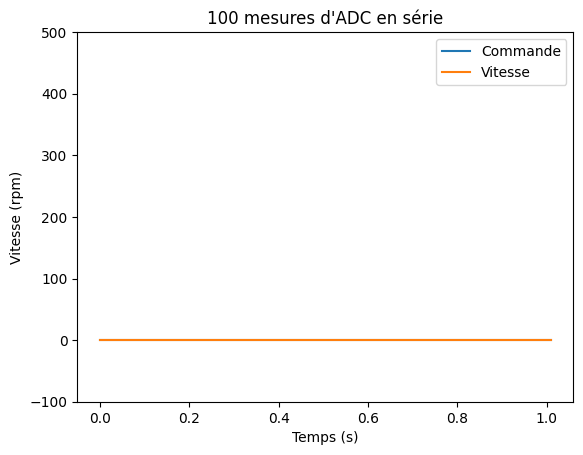

In [203]:
max_len = min(len(time_table), min(len(pwm_table),len(speed_table)))

plt.plot(time_table[0:max_len],pwm_table[0:max_len], label = "Commande")
plt.plot(time_table[0:max_len], speed_table[0:max_len], label = "Vitesse")
plt.xlabel("Temps (s)")
plt.ylim([-100, 500])
plt.ylabel("Vitesse (rpm)")
plt.title("100 mesures d'ADC en série")
plt.legend()

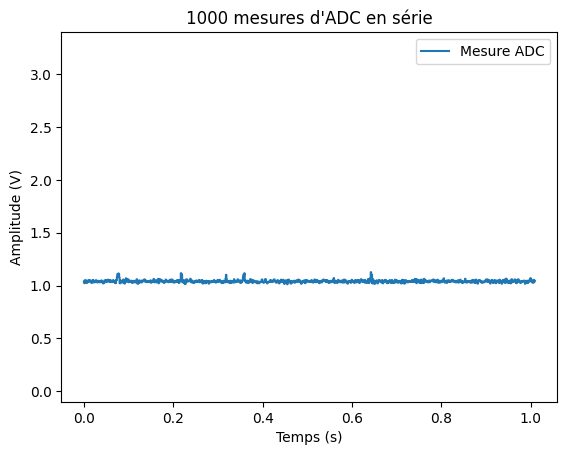

In [204]:
max_len = min(len(time_table), len(adc_table))

plt.step(time_table[0:max_len],adc_table[0:max_len], label = "Mesure ADC")#, marker = ".")
plt.xlabel("Temps (s)")
plt.ylim([-0.1, 3.4])
plt.ylabel("Amplitude (V)")
plt.title(str(len(time_table))+" mesures d'ADC en série")
plt.legend()

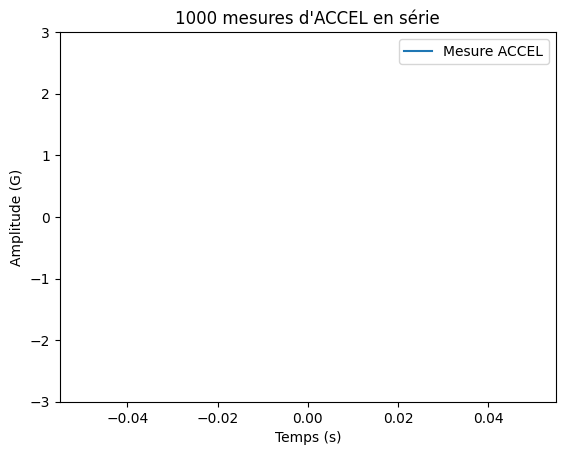

In [205]:
max_len = min(len(time_table), min(len(pwm_table),len(accel_table)))

plt.step(time_table[0:max_len],accel_table[0:max_len], label = "Mesure ACCEL")#, marker = ".")
plt.xlabel("Temps (s)")
plt.ylim([-3.0, 3.0])
plt.ylabel("Amplitude (G)")
plt.title(str(len(time_table))+" mesures d'ACCEL en série")
plt.legend()

## Post-traitement des données

### Constantes

In [ ]:
# =======================================
#   Calcul moment d'inertie du volant
# =======================================


def Iv(R, r, m):
    result = 0.5*m*(r+R)**2
    return result

def IvAtMotor(R,r, m, reduction):
    result = (1/reduction**2)*Iv(R,r,m)
    return result

r_volant = 23e-3 #m
R_volant = 148e-3 #m
m = 2.3 #kg
reduction = 15.88 #tr_e / tr_s


Ivolant = IvAtMotor(R_volant, r_volant, m, reduction)
print(Ivolant)

Imoteur = 2.5e-5 #Kg/m2

Vmax = 24 #V
Imax = 3.3 #A

### Fonctions

In [5]:
import math
import numpy as np

def Kj_moteur(speed, unit="rad.s"): #les deux variables doivent être des numpy array
    #defines the space
    result = None
    if (unit == "rad.s"):
        result = 0.5*(Imoteur + Ivolant)*(speed)**2
    elif (unit == "rpm"):
        rad_speed = speed * 2 * (np.pi/60)
        result = 0.5*(Imoteur + Ivolant)*(rad_speed)**2
    
    #to avoid spreading calculations errors
    result = math.round(result, 3)
    return result

def Kj_volant(speed, unit="rad.s"): #les deux variables doivent être des numpy array
    #defines the space
    result = None
    if (unit == "rad.s"):
        result = 0.5*(Ivolant)*(speed)**2
    elif (unit == "rpm"):
        rad_speed = speed * 2 * (np.pi/60)
        result = 0.5*(Ivolant)*(rad_speed)**2
    
    #to avoid spreading calculations errors
    result = math.round(result, 3)
    return result

def Kj_elec_moteur(current, pwm, te):
    result = np.array([0]*len(current))
    for i in range(len(current)):
        result[i] = current[i]*24*math.round(pwm[i]/1000,3)*te
    result = math.round(result, 3)
    return result

def n_rendement(out_array, in_array):
    min_len_array = min(len(out_array),len(in_array))
    result = np.array([0]*min_len_array)
    
    for i in range(min_len_array):
        result[i] = out_array[i]/in_array[i]
                        
    result = math.round(result, 3)
    return result
                        
def global_rendement(speed, unit, current, pwm, te):
    Kj_moteur = Kj_moteur(speed, unit)
    Kj_volant = Kj_volant(speed, unit)
    Kj_elec_moteur = Kj_elec_moteur(current, pwm, te)
                        
    result = n_rendement(Kj_volant, Kj_moteur)
    result = n_rendement(result, Kj_elec_moteur)
    result = math.round(result, 3)
                        
    return result

def position(p0, speed, te):
    result = np.array([0]*len(speed))
    ## Initial position
    result[0] = 0.5*speed[0]*te +p0
    for i in range(1,len(result)):
        result[i] = 0.5*speed[i]*te + speed[i-1]*te + result[0]
        
    result = math.round(result, 3)
    return result